# Demo -- cariótipo automatizado

Pega uma metáfase completa do split de teste (nunca vista em treino/validação), roda o classificador em cada cromossomo já localizado, e monta o resultado no formato clássico de cariótipo (pares organizados 1-22, X, Y) -- o jeito que um citogeneticista costuma olhar o resultado, em vez de uma lista solta de recortes.

Verde = o modelo acertou a classe daquele cromossomo. Vermelho = errou (o rótulo mostrado é o que o modelo previu; o cabeçalho da coluna é a classe verdadeira).

In [1]:
import sys
from collections import defaultdict
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

import cv2
import numpy as np
import torch
import torch.nn.functional as functional
import matplotlib.pyplot as plt

from dataset import IMAGENET_MEAN, IMAGENET_STD, load_manifest
from crops import letterbox
from evaluate import load_checkpoint
from train import CROPS_ROOT, MANIFEST
from voc_to_yolo import DENVER_CLASSES

CHECKPOINT = Path("../runs/resnet50-30epochs/best.pt")  # ajustar pro seu checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_checkpoint(CHECKPOINT, device)
print(f"Checkpoint carregado em {device}: {CHECKPOINT}")

Checkpoint carregado em cuda: ../runs/resnet50-30epochs/best.pt


In [2]:
@torch.no_grad()
def predict_crop(image_gray: np.ndarray) -> np.ndarray:
    canvas = letterbox(image_gray, size=224)
    rgb = np.stack([canvas] * 3, axis=-1).astype(np.float32) / 255.0
    rgb = (rgb - IMAGENET_MEAN) / IMAGENET_STD
    tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float().unsqueeze(0).to(device)
    logits = model(tensor)
    return functional.softmax(logits, dim=1).cpu().numpy()[0]

## Escolhe uma metáfase de exemplo

Pega a imagem do teste com mais cromossomos anotados (a mais próxima de um cariótipo completo de 46). Pra testar outra, troca `image_name` manualmente por qualquer nome que apareça em `data/processed/24_chromosomes_object/images/test/`.

In [3]:
rows = load_manifest(MANIFEST, "test")
by_image = defaultdict(list)
for row in rows:
    by_image[row["image"]].append(row)

image_name = max(by_image, key=lambda k: len(by_image[k]))
chromosomes = by_image[image_name]
print(f"Imagem: {image_name}  ({len(chromosomes)} cromossomos anotados)")

Imagem: 1080864  (50 cromossomos anotados)


In [4]:
groups = defaultdict(list)
for row in chromosomes:
    image = cv2.imread(str(CROPS_ROOT / row["path"]), cv2.IMREAD_GRAYSCALE)
    probs = predict_crop(image)
    pred_name = DENVER_CLASSES[int(probs.argmax())]
    groups[row["class_name"]].append(
        {"image": image, "true": row["class_name"], "pred": pred_name, "conf": float(probs.max())}
    )

total = len(chromosomes)
correct = sum(e["pred"] == e["true"] for es in groups.values() for e in es)
print(f"Acurácia nesta amostra: {correct}/{total} ({correct / total:.1%})")

Acurácia nesta amostra: 49/50 (98.0%)


## Cariótipo montado pelo modelo

Cada coluna é uma classe verdadeira (cabeçalho em negrito); embaixo de cada imagem está o que o modelo previu para aquele cromossomo específico.

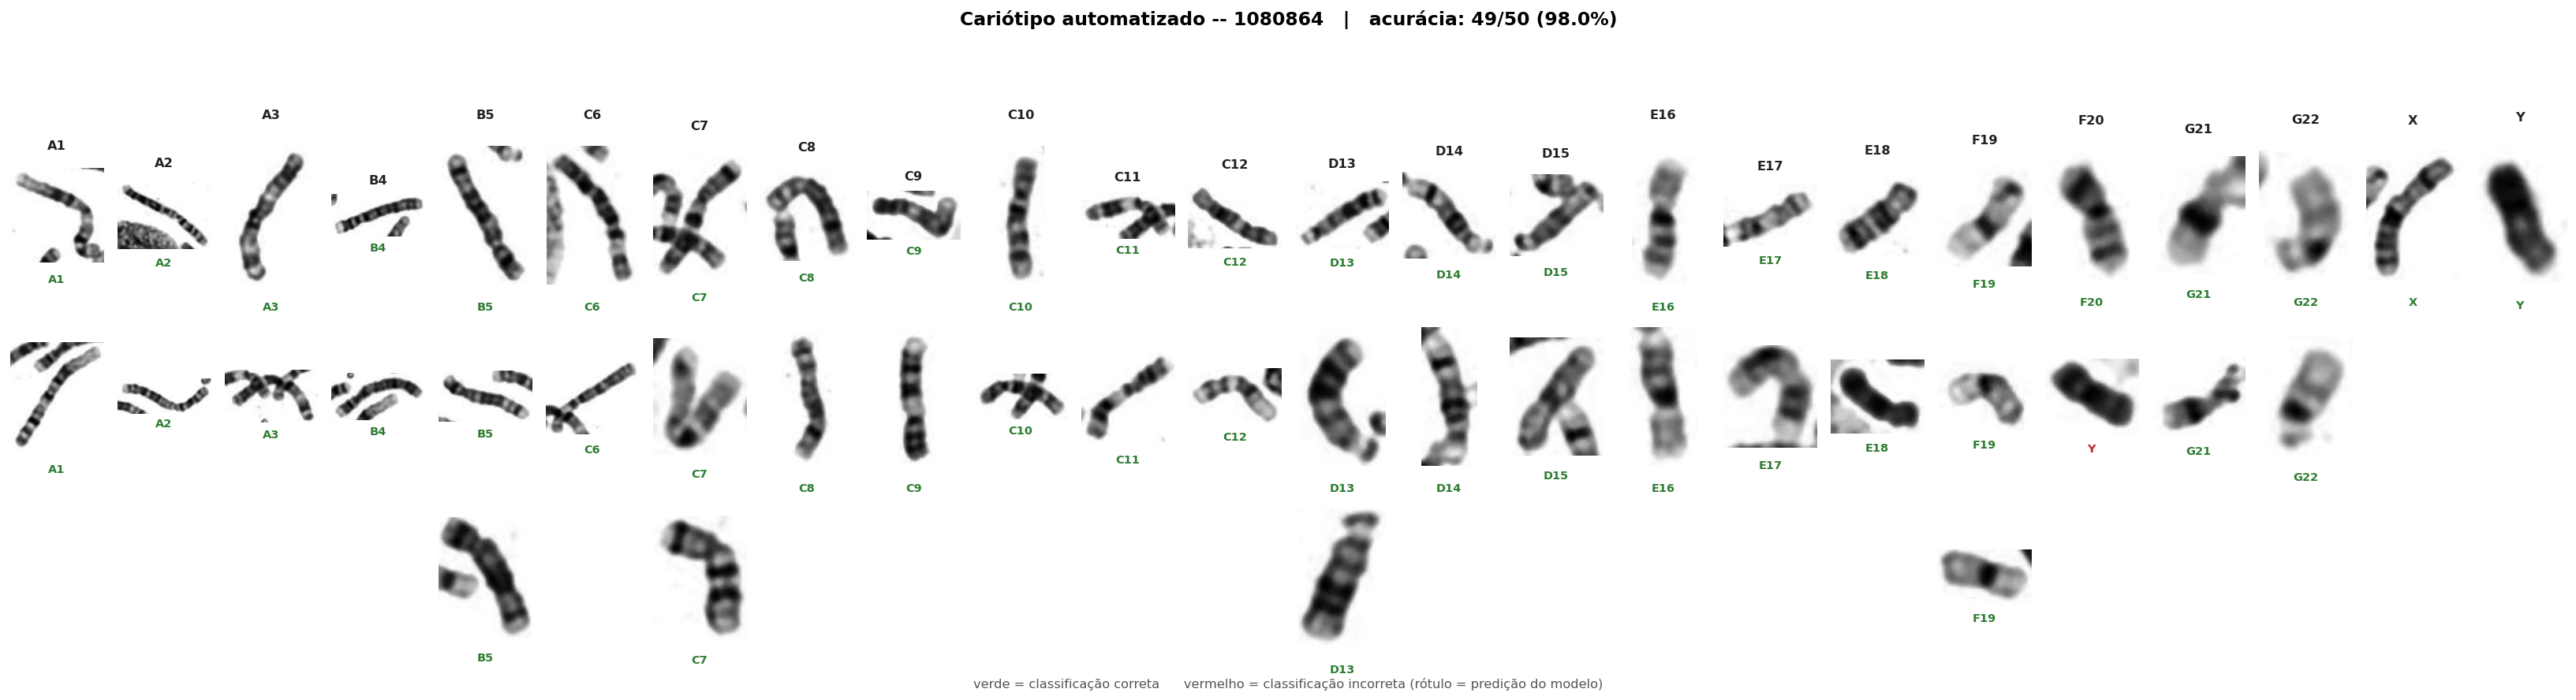

In [5]:
plt.rcParams["font.size"] = 9

n_cols = len(DENVER_CLASSES)
n_rows = max(len(groups.get(c, [])) for c in DENVER_CLASSES) or 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.05, n_rows * 1.9 + 0.6), dpi=130)
if n_rows == 1:
    axes = axes[np.newaxis, :]

for col, class_name in enumerate(DENVER_CLASSES):
    entries = groups.get(class_name, [])
    for row_i in range(n_rows):
        ax = axes[row_i, col]
        ax.axis("off")
        if row_i >= len(entries):
            continue
        entry = entries[row_i]
        ax.imshow(entry["image"], cmap="gray", interpolation="bilinear", aspect="equal")
        color = "#2e7d32" if entry["pred"] == entry["true"] else "#c62828"
        ax.text(
            0.5, -0.12, entry["pred"], transform=ax.transAxes,
            ha="center", va="top", fontsize=8, color=color, fontweight="bold",
        )
    axes[0, col].text(
        0.5, 1.18, class_name, transform=axes[0, col].transAxes,
        ha="center", va="bottom", fontsize=9, fontweight="bold", color="#222",
    )

fig.suptitle(
    f"Cariótipo automatizado -- {image_name}   |   acurácia: {correct}/{total} ({correct / total:.1%})",
    fontsize=13, fontweight="bold", y=1.04,
)
fig.text(
    0.5, -0.01,
    "verde = classificação correta      vermelho = classificação incorreta (rótulo = predição do modelo)",
    ha="center", fontsize=9, color="#555",
)
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

## Resumo em texto

Lista, em linguagem direta, quais cromossomos o modelo confundiu nesta amostra.

In [6]:
errors = [e for es in groups.values() for e in es if e["pred"] != e["true"]]

if not errors:
    print("O modelo acertou todos os cromossomos desta metáfase.")
else:
    print(f"{len(errors)} de {total} cromossomos classificados incorretamente:\n")
    for e in errors:
        print(f"  - Cromossomo do tipo {e['true']} confundido com {e['pred']} (confiança do modelo: {e['conf']:.0%})")

1 de 50 cromossomos classificados incorretamente:

  - Cromossomo do tipo F20 confundido com Y (confiança do modelo: 38%)
